In [1]:
# Start 10:38
import tensorflow as tf
import keras
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

## Load Dataset

In [2]:
DATASET_PATH = './Dataset-Vegan/'
classes = os.listdir(DATASET_PATH)
X, Y = [], []

for idx, clx in enumerate(classes):
    class_path = os.path.join(DATASET_PATH, clx)

    for raw_path in os.listdir(class_path):
        img_path = os.path.join(class_path, raw_path)

        img = keras.utils.load_img(img_path, color_mode="grayscale", target_size=(224, 224, 1))
        img = keras.utils.img_to_array(img)

        X.append(img)
        Y.append(idx)

X = np.array(X)
Y = np.array(Y)


## Preprocessing & Split

In [3]:
X = X.astype('float32') / 255.0
X_train, Xn, Y_train, Yn = train_test_split(X, Y, test_size=0.2, random_state=23)
X_val, X_test, Y_val, Y_test = train_test_split(Xn, Yn, test_size=0.5, random_state=23)

Y_train = keras.utils.to_categorical(Y_train, num_classes=len(classes))
Y_val = keras.utils.to_categorical(Y_val, num_classes=len(classes))
Y_test = keras.utils.to_categorical(Y_test, num_classes=len(classes))

## Framework

In [21]:
model = keras.Sequential([
    keras.layers.Conv2D(16, (3,3), activation="relu", input_shape=(224, 224, 1)),
    keras.layers.MaxPooling2D((2,2)),
    keras.layers.Conv2D(32, (3,3), activation="relu"),
    keras.layers.MaxPooling2D((2,2)),
    keras.layers.Conv2D(64, (3,3), activation="relu"),
    keras.layers.MaxPooling2D((2,2)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(len(classes), activation="softmax")
]) 

model.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_26 (Conv2D)              │ (None, 222, 222, 16)   │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 111, 111, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 109, 109, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 54, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 52, 52, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_26 (MaxPooling2D) │ (None, 26, 26, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 43264)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │     5,537,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,561,732 (21.22 MB)

 Trainable params: 5,561,732 (21.22 MB)

 Non-trainable params: 0 (0.00 B)

## Training

In [22]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train, Y_train,
    batch_size=32,
    epochs=10,
    validation_data=(X_val, Y_val)
)

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 235ms/step - accuracy: 0.3725 - loss: 1.3037 - val_accuracy: 0.4850 - val_loss: 1.1657
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 232ms/step - accuracy: 0.6037 - loss: 0.9751 - val_accuracy: 0.6800 - val_loss: 0.8322
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 11s 225ms/step - accuracy: 0.7588 - loss: 0.7066 - val_accuracy: 0.7350 - val_loss: 0.6514
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 239ms/step - accuracy: 0.8188 - loss: 0.5351 - val_accuracy: 0.8050 - val_loss: 0.5442
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 237ms/step - accuracy: 0.8525 - loss: 0.4353 - val_accuracy: 0.8250 - val_loss: 0.5028
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 243ms/step - accuracy: 0.8737 - loss: 0.3752 - val_accuracy: 0.8300 - val_loss: 0.4658
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 245ms/step - accuracy: 0.8838 - loss: 0.3322 - val_accuracy: 0.8550 - val_loss: 0.4191
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 11s 220ms/step - accuracy: 0.8938 - loss: 0.2992 - val_accu

In [23]:
loss, acc = model.evaluate(X_test, Y_test)
print(f"Test Loss: {loss:2f}")
print(f"Test Accuracy: {(acc*100):2f}%")

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.8550 - loss: 0.4316
Test Loss: 0.431621
Test Accuracy: 85.500002%


## Predict

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step


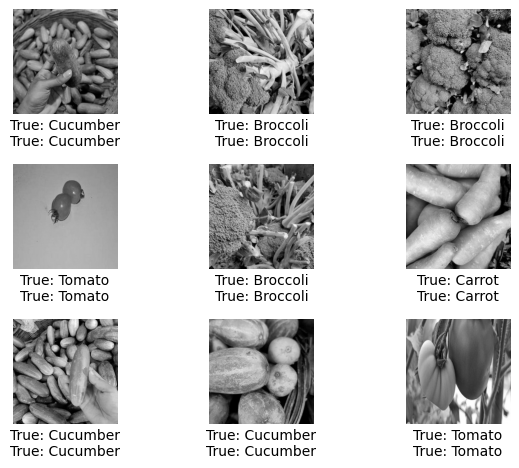

In [24]:
prediction = model.predict(X_test)
pred = np.argmax(prediction, axis=1)
true = np.argmax(Y_test, axis=1)

for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(X_test[i], cmap="gray")
    plt.axis(False)
    plt.text(0.5, -0.15, f"True: {classes[true[i]]}", ha="center", transform=plt.gca().transAxes)
    plt.text(0.5, -0.3, f"True: {classes[pred[i]]}", ha="center", transform=plt.gca().transAxes)

plt.tight_layout()
plt.show()

## Ploting

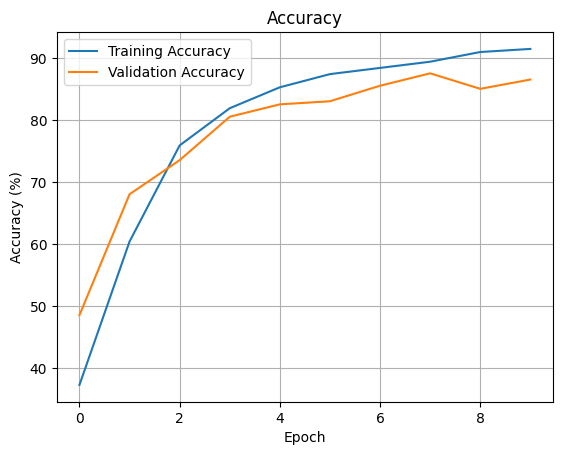

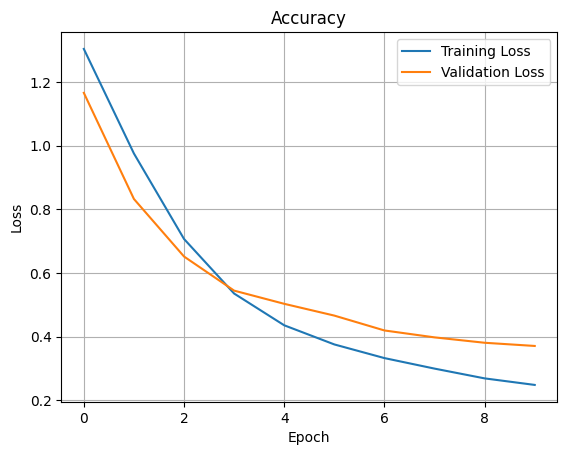

In [26]:
plt.title("Accuracy")
plt.plot([x * 100 for x in history.history['accuracy']], label="Training Accuracy")
plt.plot([x * 100 for x in history.history['val_accuracy']], label="Validation Accuracy")
plt.grid(True)
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.show()

plt.title("Accuracy")
plt.plot(history.history['loss'], label="Training Loss")
plt.plot(history.history['val_loss'], label="Validation Loss")
plt.grid(True)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()